# GLADA acoustic-feature analysis

Orchestrator for the per-group analysis: linear probes (spoof / domain /
codec), CKA vs classical acoustic descriptors, and a (K, 2)-panel t-SNE.

All heavy lifting lives in the `glada.analysis` package
(no inlined logic in notebooks):

- `extract_reps.extract_group_reps` — forward pass + per-group rep dump.
- `probing.train_linear_probe / domain_probe / codec_probe` — Alain & Bengio
  ICLR-W 2017, Pasad et al. ASRU 2021.
- `cka_acoustic.compute_cka / cka_vs_acoustic` — Kornblith et al. ICML 2019.

**Inputs:** best per-group VIB checkpoint
(`phase_a_leaveout/pergroup_vib_s42` by default; override below).

**Outputs (Drive):**
`MyDrive/Jakob/Experiments/acoustic_analysis/`:
- `group_reps_pergroup_vib_s42.pt` — saved per-group reps + audio order.
- `probe_accuracy.csv` — spoof / domain / codec probe results per group.
- `cka_vs_acoustic.csv` — per-group CKA against MFCC, spectral centroid, ZCR.
- `figures/probe_bars.png`, `figures/cka_heatmap.png`, `figures/tsne_panels.png`.


## 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q soundfile librosa scikit-learn umap-learn

import os, sys

# glada package (synced to Drive)
GLADA_PKG = '/content/drive/MyDrive/Jakob/glada_pkg'
if GLADA_PKG not in sys.path:
    sys.path.insert(0, GLADA_PKG)

import glada
from glada.analysis import (
    extract_group_reps, train_linear_probe, domain_probe, codec_probe,
    compute_cka, cka_vs_acoustic,
)
print(f'glada package from: {os.path.dirname(glada.__file__)}')


Mounted at /content/drive
glada package from: /content/drive/MyDrive/Jakob/glada_pkg/glada


## 2. Configuration

In [2]:
import glob, os

DRIVE_EXP_BASE = '/content/drive/MyDrive/Jakob/Experiments'
ANALYSIS_DIR   = os.path.join(DRIVE_EXP_BASE, 'acoustic_analysis')
FIG_DIR        = os.path.join(ANALYSIS_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Pinned run directory — the s456 full per-group VIB run from
# phase_pgvib_replicate. This is the analysis target for the
# acoustic-feature section of the report.
RUN_DIR      = '/content/drive/MyDrive/Jakob/Experiments/phase_pgvib_replicate/pergroup_vib_s456/20260507_221724'
VARIANT_NAME = 'pergroup_vib_s456'   # used to label output files
MODEL_CLASS  = 'PerGroupVIBModel'

# extract_group_reps requires a .pt checkpoint (it reads the embedded
# config dict via torch.load); best_model.safetensors is weights-only
# and would not work here. Prefer best_model.pt; fall back to the most
# recent periodic ckpt_epNN.pt if best_model.pt is missing.
ckpt_candidates = glob.glob(os.path.join(RUN_DIR, 'best_model.pt'))
if not ckpt_candidates:
    ckpt_candidates = sorted(
        glob.glob(os.path.join(RUN_DIR, 'ckpt_ep*.pt')),
        key=os.path.getmtime,
    )
assert ckpt_candidates, f'No checkpoint (best_model.pt or ckpt_ep*.pt) in {RUN_DIR}'
CHECKPOINT_PATH = ckpt_candidates[-1]

print(f'Run dir:    {RUN_DIR}')
print(f'Checkpoint: {CHECKPOINT_PATH}')

# Sample budget (guide says ~5k is enough for probes + t-SNE).
N_PER_DOMAIN = 2500


Run dir:    /content/drive/MyDrive/Jakob/Experiments/phase_pgvib_replicate/pergroup_vib_s456/20260507_221724
Checkpoint: /content/drive/MyDrive/Jakob/Experiments/phase_pgvib_replicate/pergroup_vib_s456/20260507_221724/best_model.pt


## 3. Build audio file list with labels

Balanced sample across two domains so the **domain probe** has both classes:
`N_PER_DOMAIN` files from ASVspoof 2019 LA eval and `N_PER_DOMAIN` from ITW.

Parallel arrays returned:

| array          | description                                           |
|----------------|-------------------------------------------------------|
| `audio_files`  | absolute paths in the order reps will be extracted    |
| `spoof_labels` | 0 = spoof, 1 = bonafide                               |
| `domain_labels`| 0 = ASVspoof19, 1 = ITW                               |
| `codec_labels` | A01–A19 → 0–18 for ASVspoof spoofs; -1 for everything else |


### Extract ASVspoof 2019 LA + ITW to runtime

The probes need a balanced sample from both domains. Both datasets ship as
single-tar archives in Drive; extracting once to `/content/data/` is much
faster than streaming individual files over the FUSE mount.


In [3]:
import os, tarfile

def extract_dataset(tar_path, extract_to, name):
    """Idempotent: skips if extract_to already has content."""
    if os.path.exists(extract_to) and len(os.listdir(extract_to)) > 0:
        print(f'{name}: already extracted to {extract_to}')
        return
    os.makedirs(extract_to, exist_ok=True)
    print(f'{name}: extracting {tar_path} -> {extract_to} ...')
    with tarfile.open(tar_path) as t:
        t.extractall(extract_to)
    print(f'{name}: done.')

extract_dataset(
    '/content/drive/MyDrive/Jakob/Datasets/LA.tar',
    '/content/data/asvspoof',
    'ASVspoof 2019 LA',
)
extract_dataset(
    '/content/drive/MyDrive/Jakob/Datasets/release_in_the_wild.tar',
    '/content/data/itw',
    'In-the-Wild',
)


ASVspoof 2019 LA: extracting /content/drive/MyDrive/Jakob/Datasets/LA.tar -> /content/data/asvspoof ...


/tmp/ipykernel_14193/2833426877.py:11: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(extract_to)


ASVspoof 2019 LA: done.
In-the-Wild: extracting /content/drive/MyDrive/Jakob/Datasets/release_in_the_wild.tar -> /content/data/itw ...
In-the-Wild: done.


In [4]:
import numpy as np, pandas as pd, random

random.seed(0)

# ---- ASVspoof 2019 LA eval (extracted by the eval pipeline) ----
ASV_EVAL_PROTO = '/content/data/asvspoof/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt'
ASV_EVAL_AUDIO = '/content/data/asvspoof/LA/ASVspoof2019_LA_eval/flac'
ITW_META       = '/content/data/itw/release_in_the_wild/meta.csv'
ITW_AUDIO      = '/content/data/itw/release_in_the_wild'

# Parse ASVspoof19 LA eval protocol: cols = speaker, utt, _, system_id, label
asv_rows = []
with open(ASV_EVAL_PROTO) as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) != 5:
            continue
        _spk, utt, _x, system_id, label = parts
        asv_rows.append((utt, system_id, label))
asv_df = pd.DataFrame(asv_rows, columns=['utt', 'system_id', 'label'])
asv_df['path'] = asv_df['utt'].map(lambda u: os.path.join(ASV_EVAL_AUDIO, u + '.flac'))
asv_df['spoof_label']  = (asv_df['label'] == 'bonafide').astype(int)
asv_df['domain_label'] = 0

# Codec label only meaningful for spoof rows.
def codec_idx(s):
    if not s.startswith('A'):
        return -1
    try:
        return int(s[1:]) - 1     # A01 -> 0, ..., A19 -> 18
    except ValueError:
        return -1
asv_df['codec_label'] = asv_df['system_id'].map(codec_idx)

# Stratified subsample so we get bonafide + several attack systems.
asv_sample = (
    asv_df.groupby('system_id', group_keys=False)
          .apply(lambda g: g.sample(min(len(g), max(1, N_PER_DOMAIN // asv_df['system_id'].nunique())),
                                    random_state=0))
          .head(N_PER_DOMAIN)
)
print(f'ASVspoof19 LA eval sample: {len(asv_sample)}')

# ---- ITW ----
itw_df = pd.read_csv(ITW_META)
itw_df['path'] = itw_df['file'].map(lambda f: os.path.join(ITW_AUDIO, f))
itw_df['spoof_label']  = (itw_df['label'].str.lower() == 'bona-fide').astype(int)
itw_df['domain_label'] = 1
itw_df['codec_label']  = -1
itw_sample = itw_df.sample(min(len(itw_df), N_PER_DOMAIN), random_state=0).reset_index(drop=True)
print(f'ITW sample: {len(itw_sample)}')

# ---- Combine ----
combined = pd.concat([
    asv_sample[['path', 'spoof_label', 'domain_label', 'codec_label']],
    itw_sample[['path', 'spoof_label', 'domain_label', 'codec_label']],
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)

# Filter out rows whose audio file is missing on disk.
mask = combined['path'].map(os.path.exists)
combined = combined[mask].reset_index(drop=True)

audio_files   = combined['path'].tolist()
spoof_labels  = combined['spoof_label'].to_numpy()
domain_labels = combined['domain_label'].to_numpy()
codec_labels  = combined['codec_label'].to_numpy()

print(f'Total: {len(audio_files)} files  |  '
      f'bonafide={(spoof_labels==1).sum()}  spoof={(spoof_labels==0).sum()}  |  '
      f'asv={(domain_labels==0).sum()}  itw={(domain_labels==1).sum()}')


ASVspoof19 LA eval sample: 2492
ITW sample: 2500
Total: 4992 files  |  bonafide=1735  spoof=3257  |  asv=2492  itw=2500


/tmp/ipykernel_14193/4113540171.py:38: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max(1, N_PER_DOMAIN // asv_df['system_id'].nunique())),


## 4. Extract per-group representations

In [5]:
REPS_PATH = os.path.join(ANALYSIS_DIR, f'group_reps_{VARIANT_NAME}.pt')

if os.path.exists(REPS_PATH):
    print(f'Reps already extracted: {REPS_PATH}')
else:
    extract_group_reps(
        checkpoint_path=CHECKPOINT_PATH,
        audio_files=audio_files,
        output_path=REPS_PATH,
        model_class=MODEL_CLASS,
        batch_size=16,
    )
    print(f'Saved reps -> {REPS_PATH}')

import torch
saved = torch.load(REPS_PATH, map_location='cpu', weights_only=False)
group_reps_tensor = saved['group_reps']             # (N, K, F)
K = saved['num_groups']
N, _, F = group_reps_tensor.shape
print(f'group_reps: N={N}, K={K}, F={F}')

# Per-group dict expected by probing.{domain_probe,codec_probe} and cka_acoustic.
group_reps = {k: group_reps_tensor[:, k, :].float().numpy() for k in range(K)}

# Align label arrays to whatever extract_reps actually processed
# (it preserves input order; failed loads produce None rows that are skipped).
saved_files = saved['audio_files']
keep_idx = [audio_files.index(p) for p in saved_files]
spoof_labels  = spoof_labels[keep_idx]
domain_labels = domain_labels[keep_idx]
codec_labels  = codec_labels[keep_idx]


Reps already extracted: /content/drive/MyDrive/Jakob/Experiments/acoustic_analysis/group_reps_pergroup_vib_s456.pt
group_reps: N=4992, K=3, F=256


## 5. Linear probes (spoof / domain / codec)

A leak indicator: probe accuracy near 100% on domain or codec means the
per-group GRL / VIB is *not* removing that nuisance. Probe accuracy near
chance means the group has lost that signal entirely.


In [6]:
# Spoof probe: per group separately.
spoof_results = {
    k: train_linear_probe(group_reps[k], spoof_labels, num_classes=2)
    for k in range(K)
}

# Domain probe (asv vs itw, balanced by construction).
dom_results = domain_probe(group_reps, domain_labels, num_classes=2)

# Codec probe — only meaningful on rows where codec_label >= 0
# (i.e. ASVspoof19 LA spoof samples). Subset reps + labels.
codec_mask = codec_labels >= 0
codec_subset = {k: group_reps[k][codec_mask] for k in range(K)}
codec_y = codec_labels[codec_mask]
n_codec_classes = len(np.unique(codec_y))
if codec_mask.sum() >= 200 and n_codec_classes >= 2:
    codec_results = codec_probe(codec_subset, codec_y, num_classes=n_codec_classes)
else:
    print(f'[WARN] Skipping codec probe — only {codec_mask.sum()} samples / '
          f'{n_codec_classes} classes available.')
    codec_results = {k: {'accuracy_mean': float("nan"), 'accuracy_std': 0.0} for k in range(K)}

# Tidy CSV
rows = []
for k in range(K):
    rows.append({
        'group': k,
        'spoof_acc':  spoof_results[k]['accuracy_mean'],
        'spoof_std':  spoof_results[k]['accuracy_std'],
        'domain_acc': dom_results[k]['accuracy_mean'],
        'domain_std': dom_results[k]['accuracy_std'],
        'codec_acc':  codec_results[k]['accuracy_mean'],
        'codec_std':  codec_results[k]['accuracy_std'],
    })
probe_df = pd.DataFrame(rows)
probe_csv = os.path.join(ANALYSIS_DIR, 'probe_accuracy.csv')
probe_df.to_csv(probe_csv, index=False)
print(f'Wrote {probe_csv}')
probe_df


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

Wrote /content/drive/MyDrive/Jakob/Experiments/acoustic_analysis/probe_accuracy.csv


,group,spoof_acc,spoof_std,domain_acc,domain_std,codec_acc,codec_std
0,0,0.950121,0.009253,0.983173,0.002567,0.856519,0.015312
1,1,0.948919,0.005902,0.976163,0.003544,0.774409,0.017196
2,2,0.903445,0.007671,0.955130,0.005221,0.562661,0.022896


## 6. CKA between groups and classical acoustic features

In [7]:
import numpy as np
import pandas as pd

# cka_vs_acoustic expects a 3D ndarray (N, K, F), not the per-group dict
# that the probing functions consume. Rebuild from group_reps_tensor.
G_for_cka = group_reps_tensor.float().numpy()

cka_out = cka_vs_acoustic(
    group_reps=G_for_cka,
    audio_files=saved_files,
    sr=16000,
    max_len=64000,
    n_mfcc=20,
)

# cka_out is {"matrix": (K, n_features), "feature_names": list,
# "group_indices": (K,) array}.  Pandas chokes if you hand the whole dict
# to DataFrame(...) because "matrix" is 2D — unpack the matrix + feature
# names directly.  Rows = groups, columns = acoustic features (matches
# the heatmap cell below, which uses `cka_df.columns` and
# `cka_df.to_numpy()`).
cka_matrix    = cka_out['matrix']
feature_names = cka_out['feature_names']
cka_df = pd.DataFrame(
    cka_matrix,
    index=[f'g{k}' for k in range(K)],
    columns=feature_names,
)
cka_csv = os.path.join(ANALYSIS_DIR, 'cka_vs_acoustic.csv')
cka_df.to_csv(cka_csv)
print(f'Wrote {cka_csv}')
cka_df


Wrote /content/drive/MyDrive/Jakob/Experiments/acoustic_analysis/cka_vs_acoustic.csv


,mfcc,centroid,zcr
g0,0.005007,0.001013,0.009340
g1,0.013637,0.008778,0.014300
g2,0.185360,0.013415,0.048701


## 7. Figures

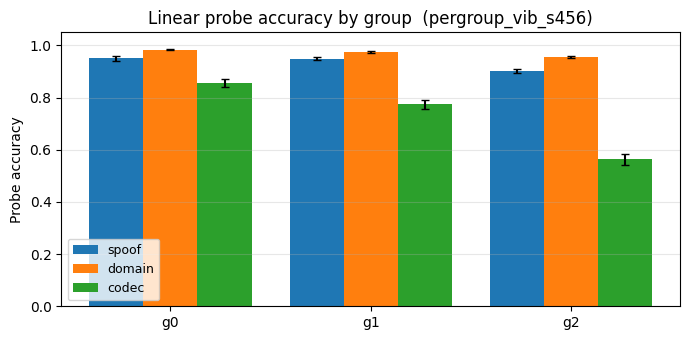

Saved /content/drive/MyDrive/Jakob/Experiments/acoustic_analysis/figures/probe_bars.png


In [8]:
import matplotlib.pyplot as plt
import numpy as np

# --- Probe accuracy bar chart (3 probes × K groups) ---
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(K)
w = 0.27
ax.bar(x - w, probe_df['spoof_acc'],  w, yerr=probe_df['spoof_std'],
       label='spoof', capsize=3)
ax.bar(x,     probe_df['domain_acc'], w, yerr=probe_df['domain_std'],
       label='domain', capsize=3)
ax.bar(x + w, probe_df['codec_acc'],  w, yerr=probe_df['codec_std'],
       label='codec',  capsize=3)
ax.set_xticks(x); ax.set_xticklabels([f'g{k}' for k in range(K)])
ax.set_ylim(0, 1.05); ax.set_ylabel('Probe accuracy'); ax.grid(axis='y', alpha=0.3)
ax.set_title(f'Linear probe accuracy by group  ({VARIANT_NAME})')
ax.legend(loc='lower left', fontsize=9)
fig.tight_layout()
out = os.path.join(FIG_DIR, 'probe_bars.png')
fig.savefig(out, dpi=150); plt.show()
print(f'Saved {out}')


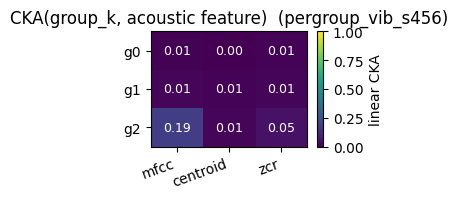

Saved /content/drive/MyDrive/Jakob/Experiments/acoustic_analysis/figures/cka_heatmap.png


In [9]:
# --- CKA heatmap ---
features = list(cka_df.columns)
M = cka_df.to_numpy()                 # (K, n_features)

fig, ax = plt.subplots(figsize=(0.7 + 0.7 * len(features), 0.6 + 0.5 * K))
im = ax.imshow(M, aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=20, ha='right')
ax.set_yticks(range(K)); ax.set_yticklabels([f'g{k}' for k in range(K)])
for i in range(K):
    for j in range(len(features)):
        ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center',
                color=('white' if M[i, j] < 0.5 else 'black'), fontsize=9)
plt.colorbar(im, ax=ax, label='linear CKA')
ax.set_title(f'CKA(group_k, acoustic feature)  ({VARIANT_NAME})')
fig.tight_layout()
out = os.path.join(FIG_DIR, 'cka_heatmap.png')
fig.savefig(out, dpi=150); plt.show()
print(f'Saved {out}')


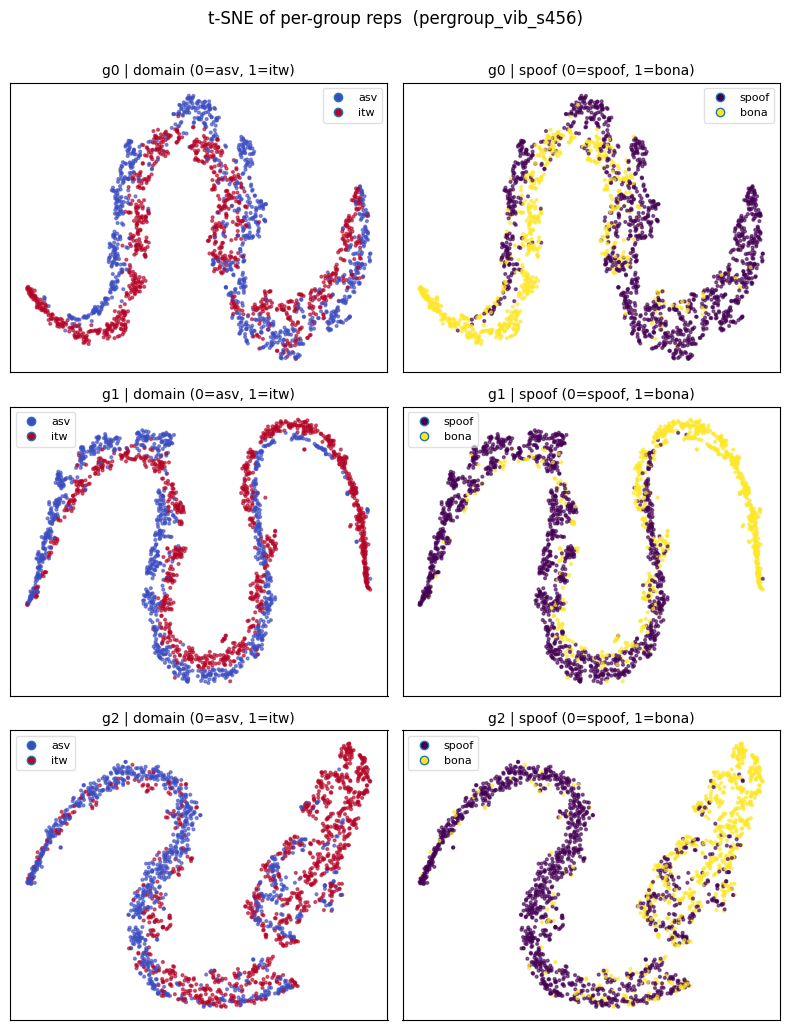

Saved /content/drive/MyDrive/Jakob/Experiments/acoustic_analysis/figures/tsne_panels.png


In [10]:
# --- t-SNE: K rows (groups) x 2 columns (domain / spoof colorings) ---
from sklearn.manifold import TSNE

# Subsample for t-SNE speed; perplexity 30 is the standard default.
N_TSNE = min(2000, len(saved_files))
idx = np.random.RandomState(0).choice(len(saved_files), size=N_TSNE, replace=False)
sub_dom = domain_labels[idx]
sub_spf = spoof_labels[idx]

fig, axes = plt.subplots(K, 2, figsize=(8, 3.4 * K), squeeze=False)
for k in range(K):
    Xk = group_reps[k][idx]
    emb = TSNE(n_components=2, perplexity=30, init='pca',
               random_state=0).fit_transform(Xk)
    for col, (color_arr, title_suffix, cmap, labels) in enumerate([
        (sub_dom, 'domain (0=asv, 1=itw)', 'coolwarm',  ['asv', 'itw']),
        (sub_spf, 'spoof (0=spoof, 1=bona)', 'viridis',  ['spoof', 'bona']),
    ]):
        ax = axes[k, col]
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=color_arr, cmap=cmap, s=4, alpha=0.6)
        ax.set_title(f'g{k} | {title_suffix}', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        # Discrete legend
        handles = [plt.Line2D([0], [0], marker='o', linestyle='', markersize=6,
                              markerfacecolor=plt.get_cmap(cmap)(c)) for c in [0.0, 1.0]]
        ax.legend(handles, labels, loc='best', fontsize=8, framealpha=0.6)
fig.suptitle(f't-SNE of per-group reps  ({VARIANT_NAME})', y=1.005)
fig.tight_layout()
out = os.path.join(FIG_DIR, 'tsne_panels.png')
fig.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved {out}')


## 8. Notes for the report

Reading the figures:

- **Probe bars** — domain accuracy near chance (~0.5) means the per-group
  GRL has scrubbed the domain signal from that group. Spoof accuracy *high*
  on every group is expected; codec accuracy *high* on g0 specifically would
  back the "g0 carries the codec/artifact signal" claim.
- **CKA heatmap** — g0 should align highest with MFCC and centroid (low-level
  spectral features); higher groups should align less. If the heatmap is
  flat across groups, the hierarchical specialisation claim is weaker.
- **t-SNE panels** — looking for a *domain* coloring that is *not* visibly
  separable in the per-group reps post-VIB. If domain clusters are obvious,
  GRL is failing.

CSVs (`probe_accuracy.csv`, `cka_vs_acoustic.csv`) drop directly into the
acoustic-analysis subsection of the thesis chapter and the ICTAI paper.
